In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score

diabetes = load_diabetes()

X = diabetes.data
y = diabetes.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(
    y_train,
    dtype=torch.float32
).reshape(-1, 1)

y_test = torch.tensor(
    y_test,
    dtype=torch.float32
).reshape(-1, 1)



def create_model():

    input_size = X_train.shape[1]

    model = nn.Sequential(

        nn.Linear(input_size, 64),
        nn.ReLU(),

        nn.Linear(64, 32),
        nn.ReLU(),

        nn.Linear(32, 16),
        nn.ReLU(),

        nn.Linear(16, 1)
    )

    return model


def train_model(weight_decay):

    # Однаковий початковий стан для експериментів
    torch.manual_seed(42)

    model = create_model()

    # Створення навчального набору
    train_dataset = TensorDataset(X_train, y_train)

    # Однаковий порядок перемішування даних
    generator = torch.Generator().manual_seed(42)

    train_loader = DataLoader(
        train_dataset,
        batch_size=32,
        shuffle=True,
        generator=generator
    )

    # Функція втрат
    criterion = nn.MSELoss()

    # Оптимізатор Adam
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001,
        weight_decay=weight_decay
    )

    epochs = 50

    train_losses = []

    # Навчання
    for epoch in range(epochs):

        model.train()

        running_loss = 0.0
        total = 0

        for inputs, labels in train_loader:

            optimizer.zero_grad()

            outputs = model(inputs)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            total += inputs.size(0)

        epoch_loss = running_loss / total

        train_losses.append(epoch_loss)

        print(
            f"Epoch [{epoch + 1}/{epochs}] "
            f"| Loss: {epoch_loss:.4f}"
        )

    return model, train_losses



print("\n========== БЕЗ РЕГУЛЯРИЗАЦІЇ ==========")

model_without, losses_without = train_model(
    weight_decay=0
)



print("\n========== З L2-РЕГУЛЯРИЗАЦІЄЮ ==========")

model_with, losses_with = train_model(
    weight_decay=1e-4
)



def evaluate_model(model):

    model.eval()

    with torch.no_grad():

        predictions = model(X_test)

    # Перетворення тензорів у NumPy
    y_pred = predictions.numpy().flatten()
    y_true = y_test.numpy().flatten()

    # Обчислення MAE
    mae = mean_absolute_error(y_true, y_pred)

    # Обчислення R2
    r2 = r2_score(y_true, y_pred)

    return mae, r2


# Результати першої моделі
mae_without, r2_without = evaluate_model(model_without)

# Результати другої моделі
mae_with, r2_with = evaluate_model(model_with)


results = pd.DataFrame({

    "Конфігурація": [
        "Без регуляризації",
        "З регуляризацією (L2)"
    ],

    "MAE": [
        mae_without,
        mae_with
    ],

    "R2": [
        r2_without,
        r2_with
    ]
})

print("\n========== ПОРІВНЯННЯ РЕЗУЛЬТАТІВ ==========")

print(results.to_string(
    index=False,
    formatters={
        "MAE": "{:.4f}".format,
        "R2": "{:.4f}".format
    }
))



print("\n========== TRAINING LOSS ==========")

print(f"Без регуляризації: {losses_without[-1]:.4f}")
print(f"З L2-регуляризацією: {losses_with[-1]:.4f}")



========== БЕЗ РЕГУЛЯРИЗАЦІЇ ==========
Epoch [1/50] | Loss: 29636.9776
Epoch [2/50] | Loss: 29615.6133
Epoch [3/50] | Loss: 29571.6242
Epoch [4/50] | Loss: 29473.3351
Epoch [5/50] | Loss: 29267.6963
Epoch [6/50] | Loss: 28898.2657
Epoch [7/50] | Loss: 28180.3255
Epoch [8/50] | Loss: 26952.4303
Epoch [9/50] | Loss: 24886.7221
Epoch [10/50] | Loss: 21915.6710
Epoch [11/50] | Loss: 17916.9705
Epoch [12/50] | Loss: 13333.3906
Epoch [13/50] | Loss: 9177.5555
Epoch [14/50] | Loss: 6269.5710
Epoch [15/50] | Loss: 5061.5502
Epoch [16/50] | Loss: 4769.8321
Epoch [17/50] | Loss: 4578.6433
Epoch [18/50] | Loss: 4376.9530
Epoch [19/50] | Loss: 4204.3411
Epoch [20/50] | Loss: 4077.8747
Epoch [21/50] | Loss: 4018.6039
Epoch [22/50] | Loss: 3928.6324
Epoch [23/50] | Loss: 3832.5501
Epoch [24/50] | Loss: 3743.0162
Epoch [25/50] | Loss: 3674.7698
Epoch [26/50] | Loss: 3611.3379
Epoch [27/50] | Loss: 3582.2141
Epoch [28/50] | Loss: 3561.1564
Epoch [29/50] | Loss: 3507.8426
Epoch [30/50] | Loss: 3449.3

In [2]:
#  task4

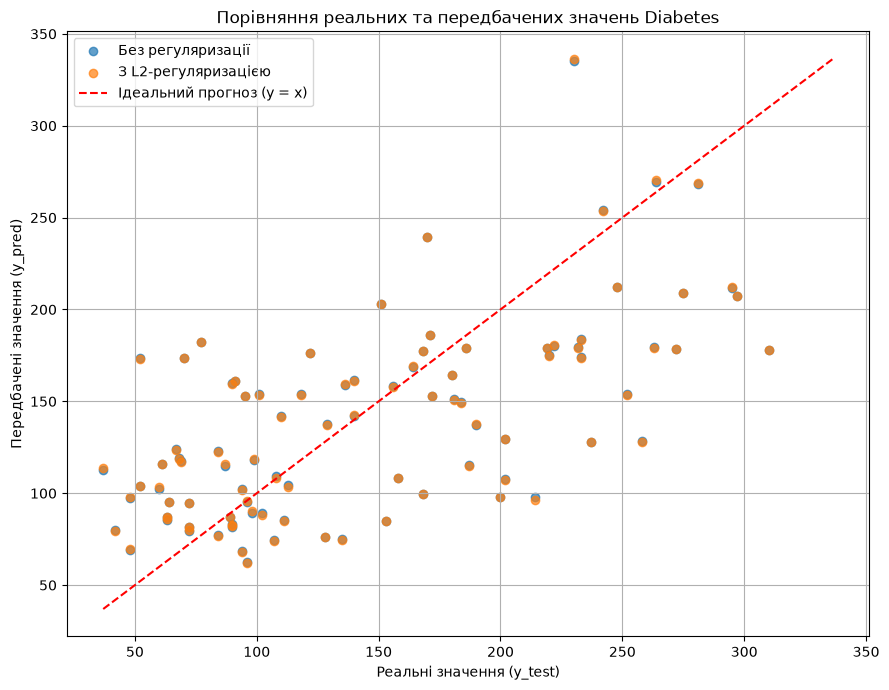

In [4]:
import matplotlib.pyplot as plt
# Отримання прогнозів обох моделей
model_without.eval()
model_with.eval()

with torch.no_grad():
    y_pred_without = model_without(X_test).numpy().flatten()
    y_pred_with = model_with(X_test).numpy().flatten()

y_true = y_test.numpy().flatten()

# Межі для діагоналі y = x
min_value = min(y_true.min(), y_pred_without.min(), y_pred_with.min())
max_value = max(y_true.max(), y_pred_without.max(), y_pred_with.max())

# Побудова графіків
plt.figure(figsize=(9, 7))

# Прогнози без регуляризації
plt.scatter(
    y_true,
    y_pred_without,
    alpha=0.7,
    label="Без регуляризації"
)

# Прогнози з L2-регуляризацією
plt.scatter(
    y_true,
    y_pred_with,
    alpha=0.7,
    label="З L2-регуляризацією"
)

# Ідеальна діагональ y = x
plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    label="Ідеальний прогноз (y = x)"
)

plt.xlabel("Реальні значення (y_test)")
plt.ylabel("Передбачені значення (y_pred)")
plt.title("Порівняння реальних та передбачених значень Diabetes")
plt.legend()
plt.grid(True)
plt.tight_layout()

# Збереження графіка
plt.savefig(
    "diabetes_healthrisk_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
